## Education Project
Can socioeconomic factors predict ACT scores?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [2]:
edgap= pd.read_excel(r"C:\Users\Owner\Documents\Graduate School\Fall 2026 Quarter\DATA 5100- Foundation of Data Science\Education Project 5100\data-education\EdGap_data.xlsx", dtype = {'NCESSCH School ID':object})

C:\Users\Owner\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [3]:
school_information= pd.read_csv(r"C:\Users\Owner\Documents\Graduate School\Fall 2026 Quarter\DATA 5100- Foundation of Data Science\Education Project 5100\data-education\ccd_sch_029_1617_w_1a_11212017.csv", encoding = 'unicode_escape')

C:\Users\Owner\AppData\Local\Temp\ipykernel_16532\2655317789.py:1: DtypeWarning: Columns (0: STATE_AGENCY_NO, 1: LEAID, 2: MSTREET2, 3: MSTREET3, 4: MZIP, 5: MZIP4, 6: LSTREET2, 7: LSTREET3, 8: LZIP, 9: LZIP4, 10: SY_STATUS, 11: UPDATED_STATUS, 12: SCH_TYPE, 13: CHARTAUTH1, 14: CHARTAUTH2, 15: CHARTAUTHN2) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information= pd.read_csv(r"C:\Users\Owner\Documents\Graduate School\Fall 2026 Quarter\DATA 5100- Foundation of Data Science\Education Project 5100\data-education\ccd_sch_029_1617_w_1a_11212017.csv", encoding = 'unicode_escape')


In [4]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [5]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,...,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [6]:
pd.set_option('display.max_columns',None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [7]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [8]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

## Inital assessment of Data Frames
- School_info dataset is huge compared to Edgap dataset
- Edgap data set doesnt include all the schools. 
- Each dataset has missing values but is tidy or long format
- School identifier is an object in Edgap but a float in school_info data set

# Is Data Sufficient For Answering The Question?
Working with regression analysis to see relationship of ACT score vs. various socioeconomic factors
pairplot- shows scatter plots of all pairwise relationships between variables AND histograms of individiaul variables(to see distribution)

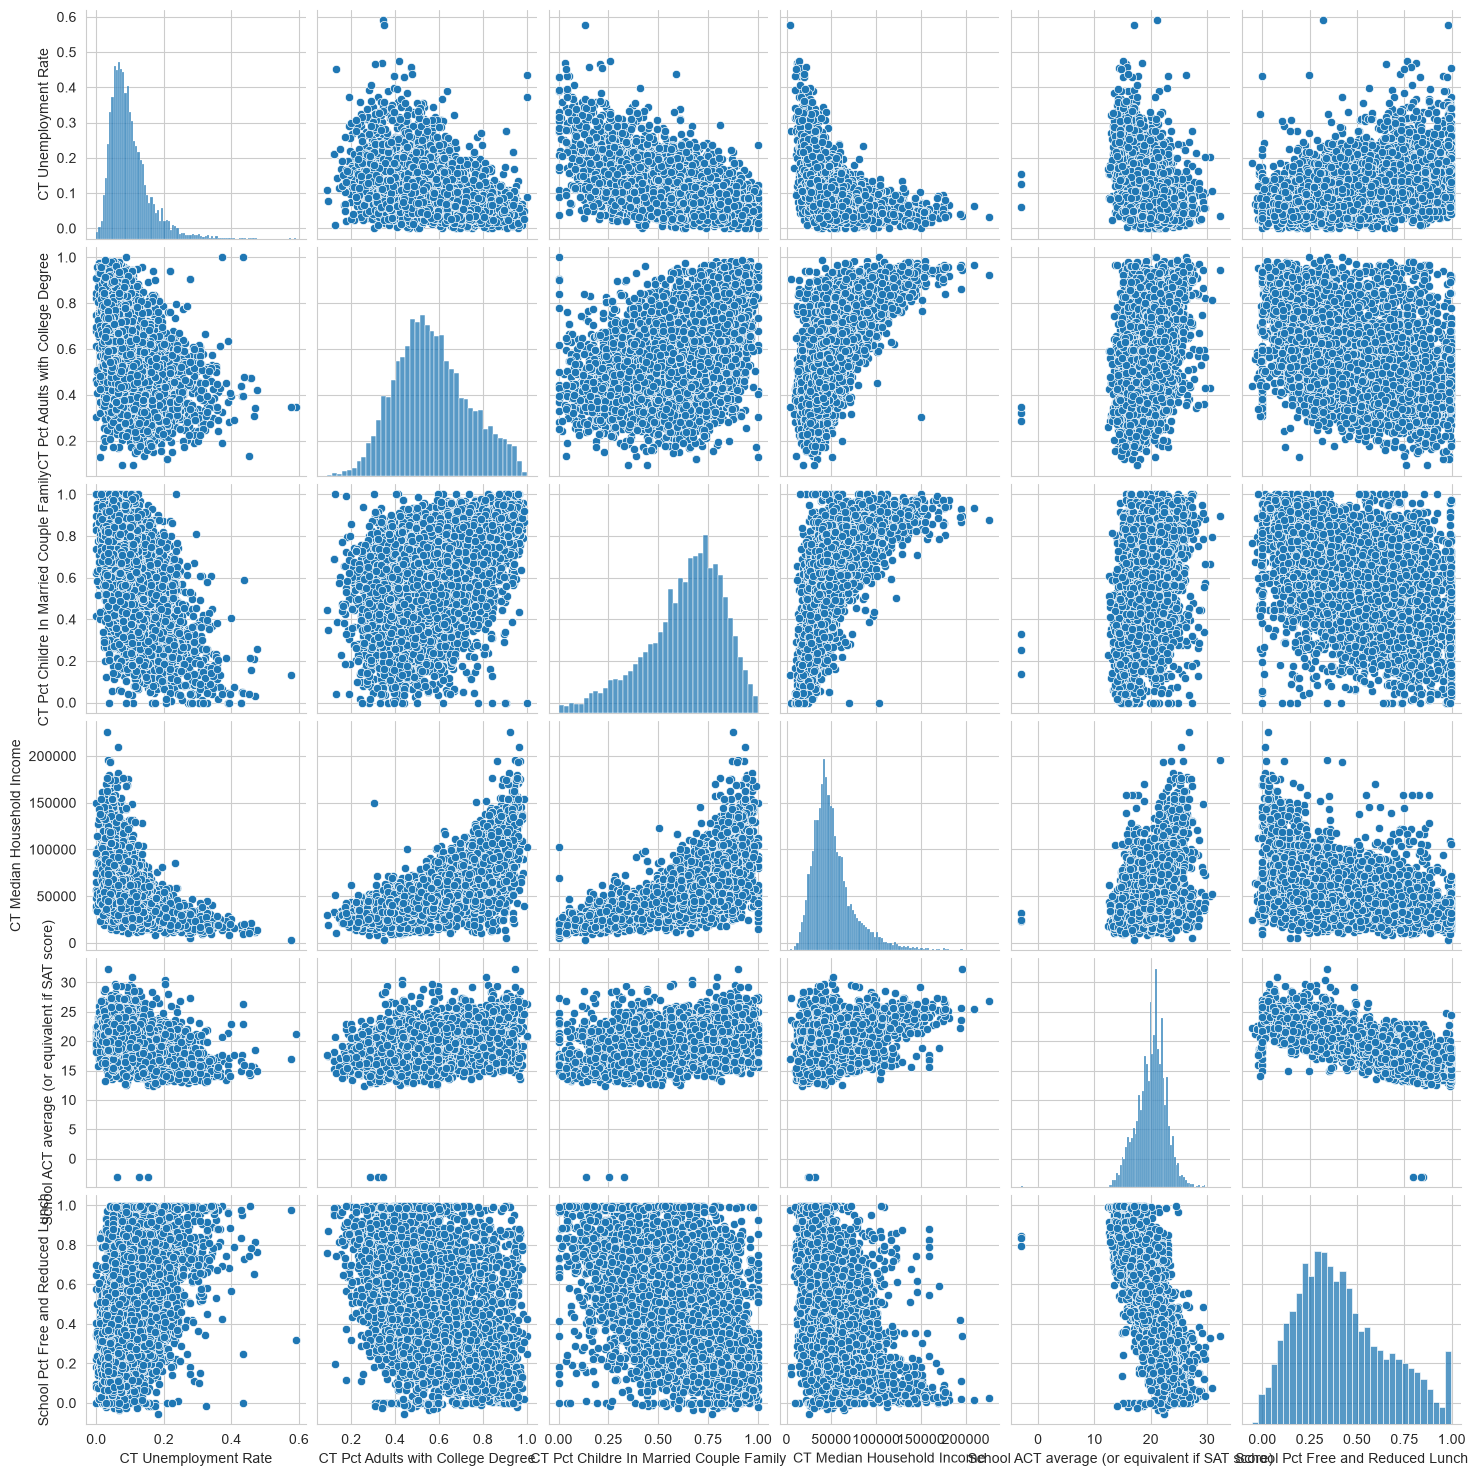

In [9]:
sns.pairplot(
    edgap.drop(columns="NCESSCH School ID")
);
plt.show()

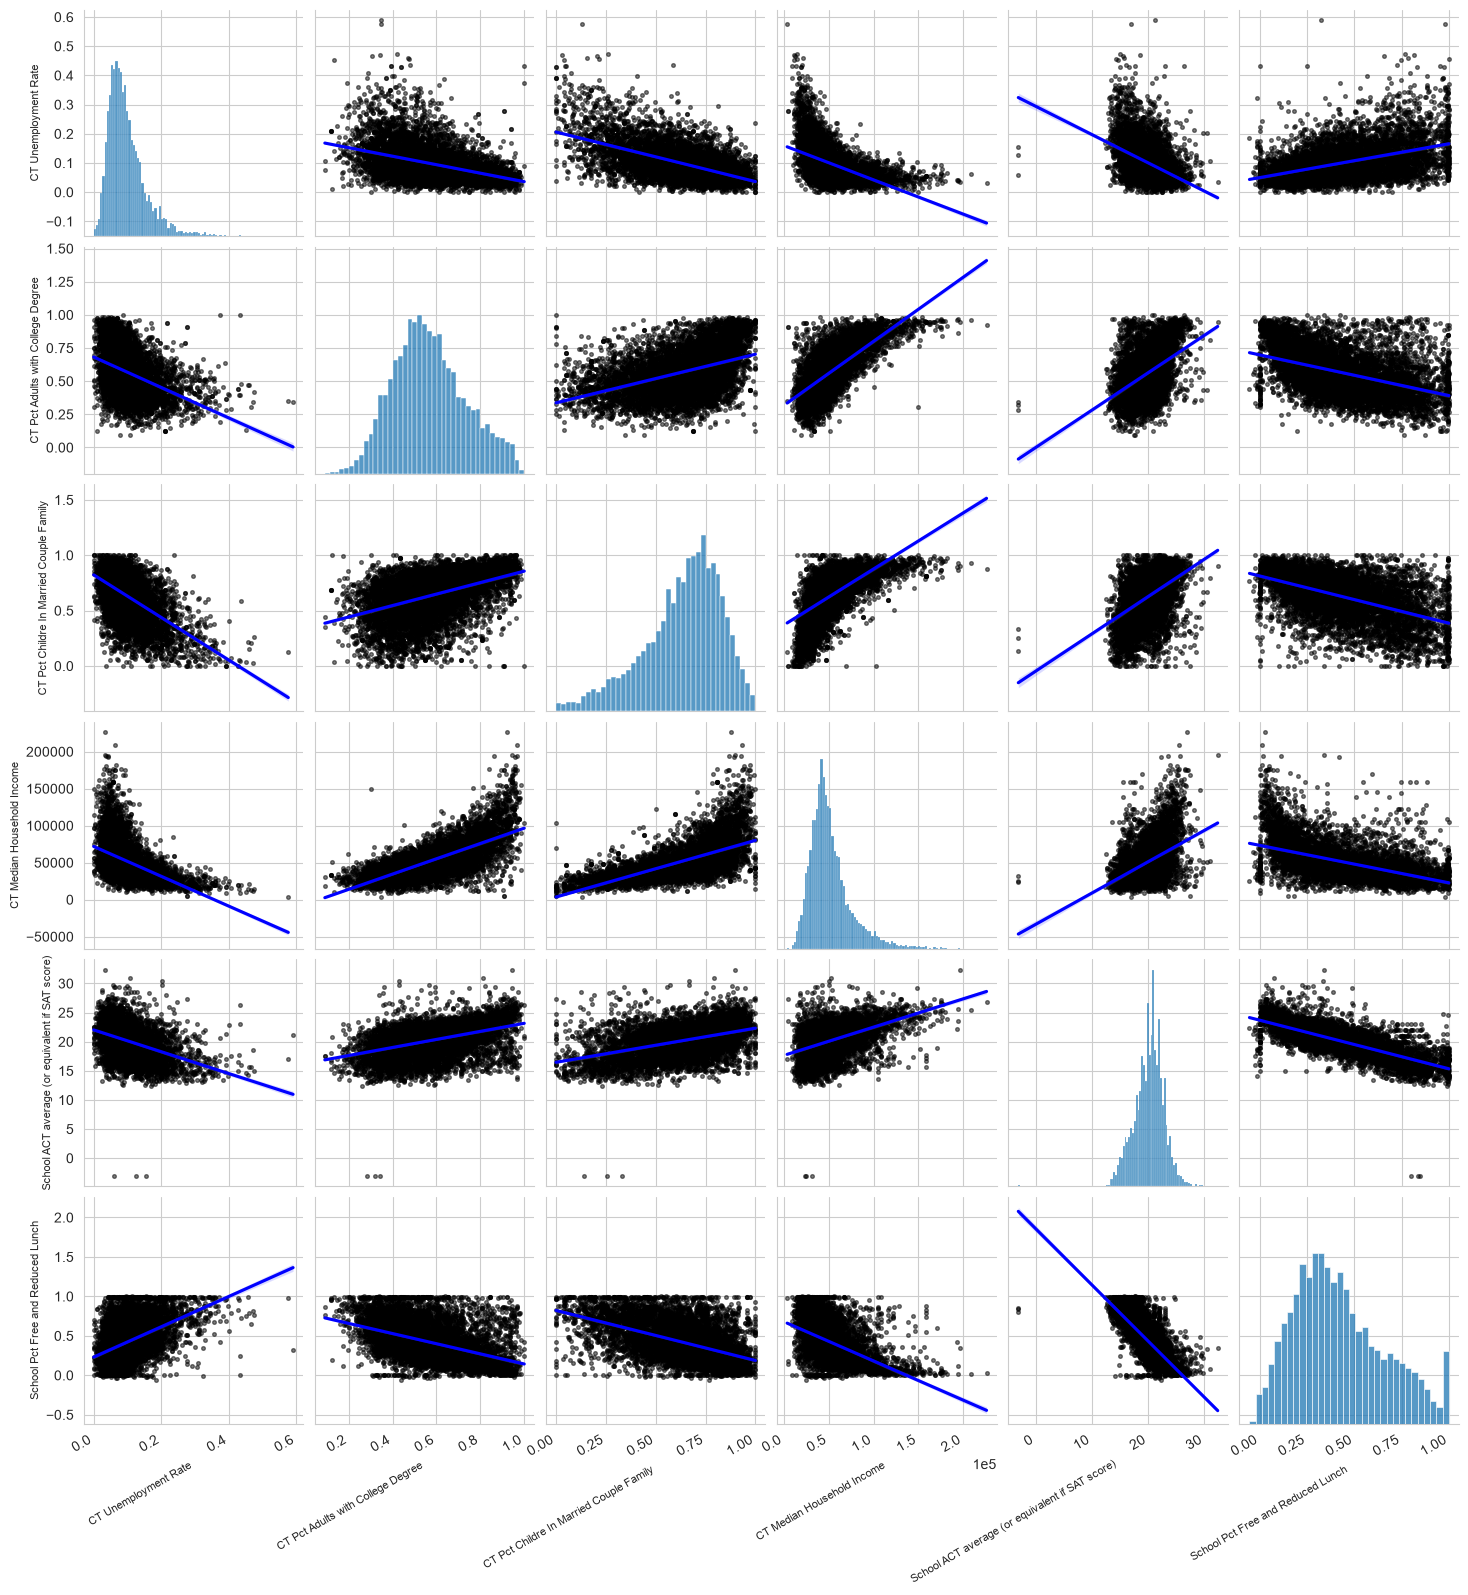

In [10]:
fig = sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"), 
    kind = "reg", 
    plot_kws={
        "line_kws":{"color":"blue"},
        "scatter_kws": {"alpha": 0.5, "color":"k", "s":7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == "CT Median Household Income":
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits=(0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation=30, ha ='right')

plt.show()

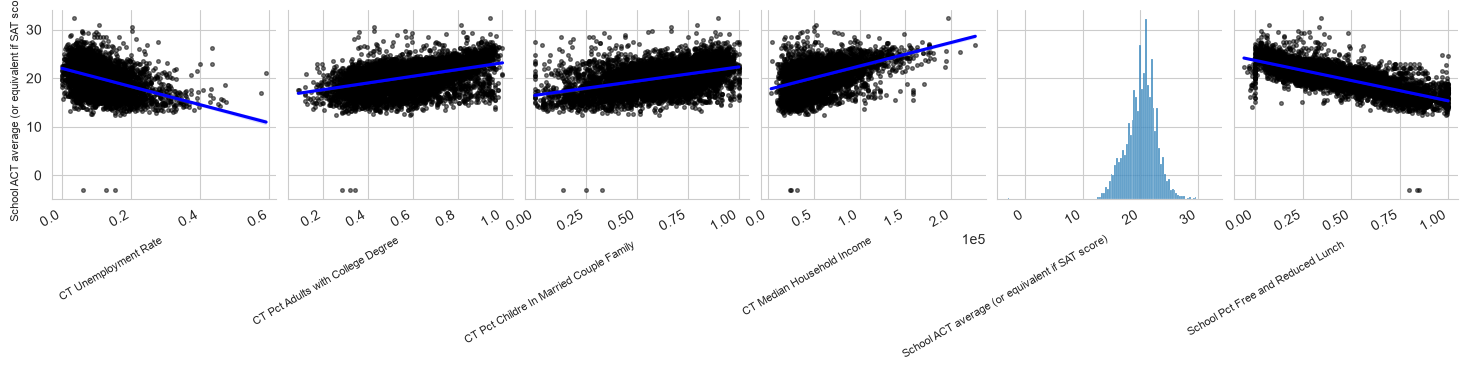

In [11]:
fig = sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"), 
    y_vars=['School ACT average (or equivalent if SAT score)'],
    kind = "reg", 
    plot_kws={
        "line_kws":{"color":"blue"},
        "scatter_kws": {"alpha": 0.5, "color":"k", "s":7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == "CT Median Household Income":
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits=(0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation=30, ha ='right')

plt.show()

initial variable impressions
- There appears to be relationship between socioeconomic variables and ACT score.
- There are some out of range ACT and percent lunch values 
- All in all data set is a good candidate to answer the question

## Data Prep

In [12]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH','LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
    ]

In [13]:
school_information = school_information.rename(
    columns={
        "SCHOOL_YEAR": 'year',
        "NCESSCH": 'id',
        "LSTATE": 'state',
        "LZIP": 'zip_code',
        "SCH_TYPE_TEXT": 'school_type',
        "LEVEL": 'school_level',
        "CHARTER_TEXT": 'charter'
    }
)

In [14]:
edgap = edgap.rename(
    columns = {
        "NCESSCH School ID": "id",
        "CT Pct Adults with College Degree": "percent_college",
        "CT Unemployment Rate": "rate_unemployment",
        "CT Pct Childre In Married Couple Family": "percent_married",
        "CT Median Household Income": "median_income",
        "School ACT average (or equivalent if SAT score)": "average_act",
        "School Pct Free and Reduced Lunch": "percent_lunch",
    }
)
        

In [15]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [16]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


Join Data Frames and Quality Control

In [17]:
school_information['id'] = school_information['id'].astype('object')

In [18]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  str   
 1   id            102181 non-null  object
 2   state         102183 non-null  str   
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  str   
 5   school_level  102179 non-null  str   
 6   charter       102179 non-null  str   
dtypes: object(2), str(5)
memory usage: 9.0+ MB


In [19]:
df= edgap.merge(
    school_information, 
    how= 'left',
    on = 'id'
)

In [20]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   str    
 11  school_level       7898 non-null   str    
 12  charter            7898 non-null   str    
dtypes: float64(6), object(2), str(5)
memory usage: 1.0+ MB


In [22]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


In [23]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


In [24]:
df.loc[df['percent_lunch'] <0, 'percent_lunch'] = np.nan
df.loc[df['average_act'] <1, 'average_act']=np.nan

In [25]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [26]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [27]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

In [28]:
df= df.loc[df['school_level'] == 'High']

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


In [31]:
percent_missing = df.isna().mean().round(4)*100
percent_missing.to_frame(name='Percent Missing Values')

,Percent Missing Values
id,0.00
rate_unemployment,0.17
percent_college,0.15
percent_married,0.28
median_income,0.22
average_act,0.04
percent_lunch,0.28
year,0.00
state,0.00
zip_code,0.00


In [32]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [33]:
df['state'].nunique()

20

In [34]:
import plotly.offline as po
import plotly.graph_objs as pg

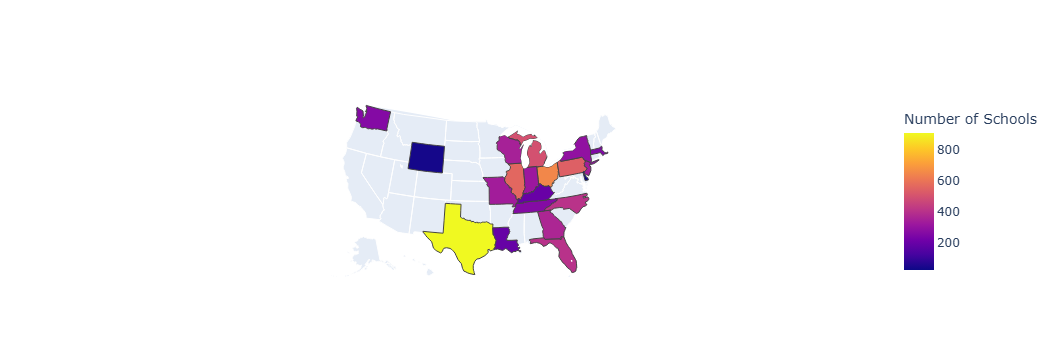

In [35]:
layout = dict(
    geo={"scope": "usa"}, coloraxis_colorbar = dict (title = "Number of Schools")
)
data = dict(
    type = "choropleth",
    locations = df ["state"].value_counts().index,
    locationmode= "USA-states",
    z= df["state"].value_counts().values,
    coloraxis="coloraxis",
)
x = pg.Figure(data = [data], layout =layout)
po.iplot(x)

In [36]:
df=df.dropna(subset=['average_act'])

In [37]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


Impute Missing values in Socioeconomic Variables

In [38]:
predictor_variables= [
    'rate_unemployment',
    'percent_college',
    "percent_married",
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

In [39]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [40]:
imputer = IterativeImputer()

In [41]:
numerical_predictors = df[predictor_variables].select_dtypes(include ='number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


In [42]:
imputer.fit(df.loc[:, numerical_predictors])

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",10
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.001
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'
,"skip_complete skip_complete: bool, default=FalseIf `True` then features with missing values during :meth:`transform`which did not have any missing values during :meth:`fit` will beimputed with the initial imputation method only. Set to `True` if youhave many features with no missing values at both :meth:`fit` and:meth:`transform` time to save compute.",False
,"min_value min_value: float or array-like of shape (n_features,), default=-np.infMinimum possible imputed value. Broadcast to shape `(n_features,)` ifscalar. If array-like, expects shape `(n_features,)`, one min value foreach feature. The default is `-np.inf`... versionchanged:: 0.23 Added support for array-like.",-inf


In [43]:
df.loc[:,numerical_predictors]=imputer.transform(df.loc[:,numerical_predictors])

In [44]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


In [45]:
df.to_csv(
    'education_clean.csv',
    encoding = 'utf-8-sig',
    index = False
)

## Exploratory Analysis

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [47]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


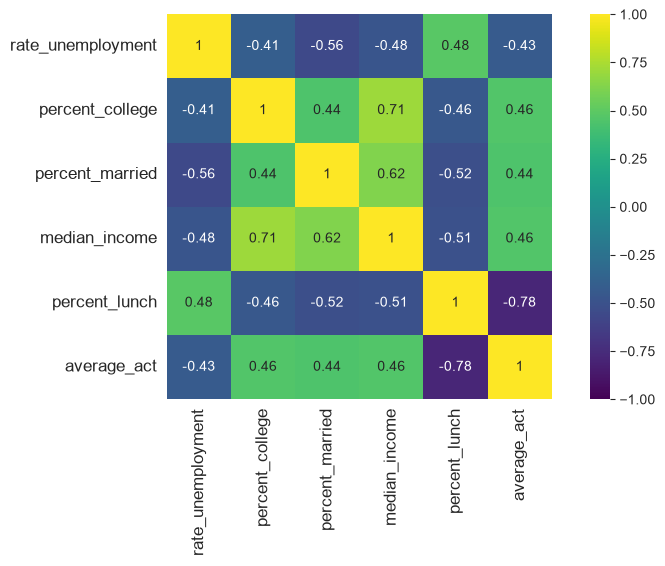

In [48]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch','state']
numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()
corr_matrix = df[numerical_predictors + ['average_act']].corr()
plt.figure(figsize = (10,5))
sns.heatmap(
    corr_matrix, vmax=1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)
plt.tick_params(labelsize = 12)
plt.show()

heat map impressions
- notable correlation with percent_lunch and average_act
- notable correlation between median_income and percent_college and percent_married
- notable correlation between percent_married and rate_unemployment  

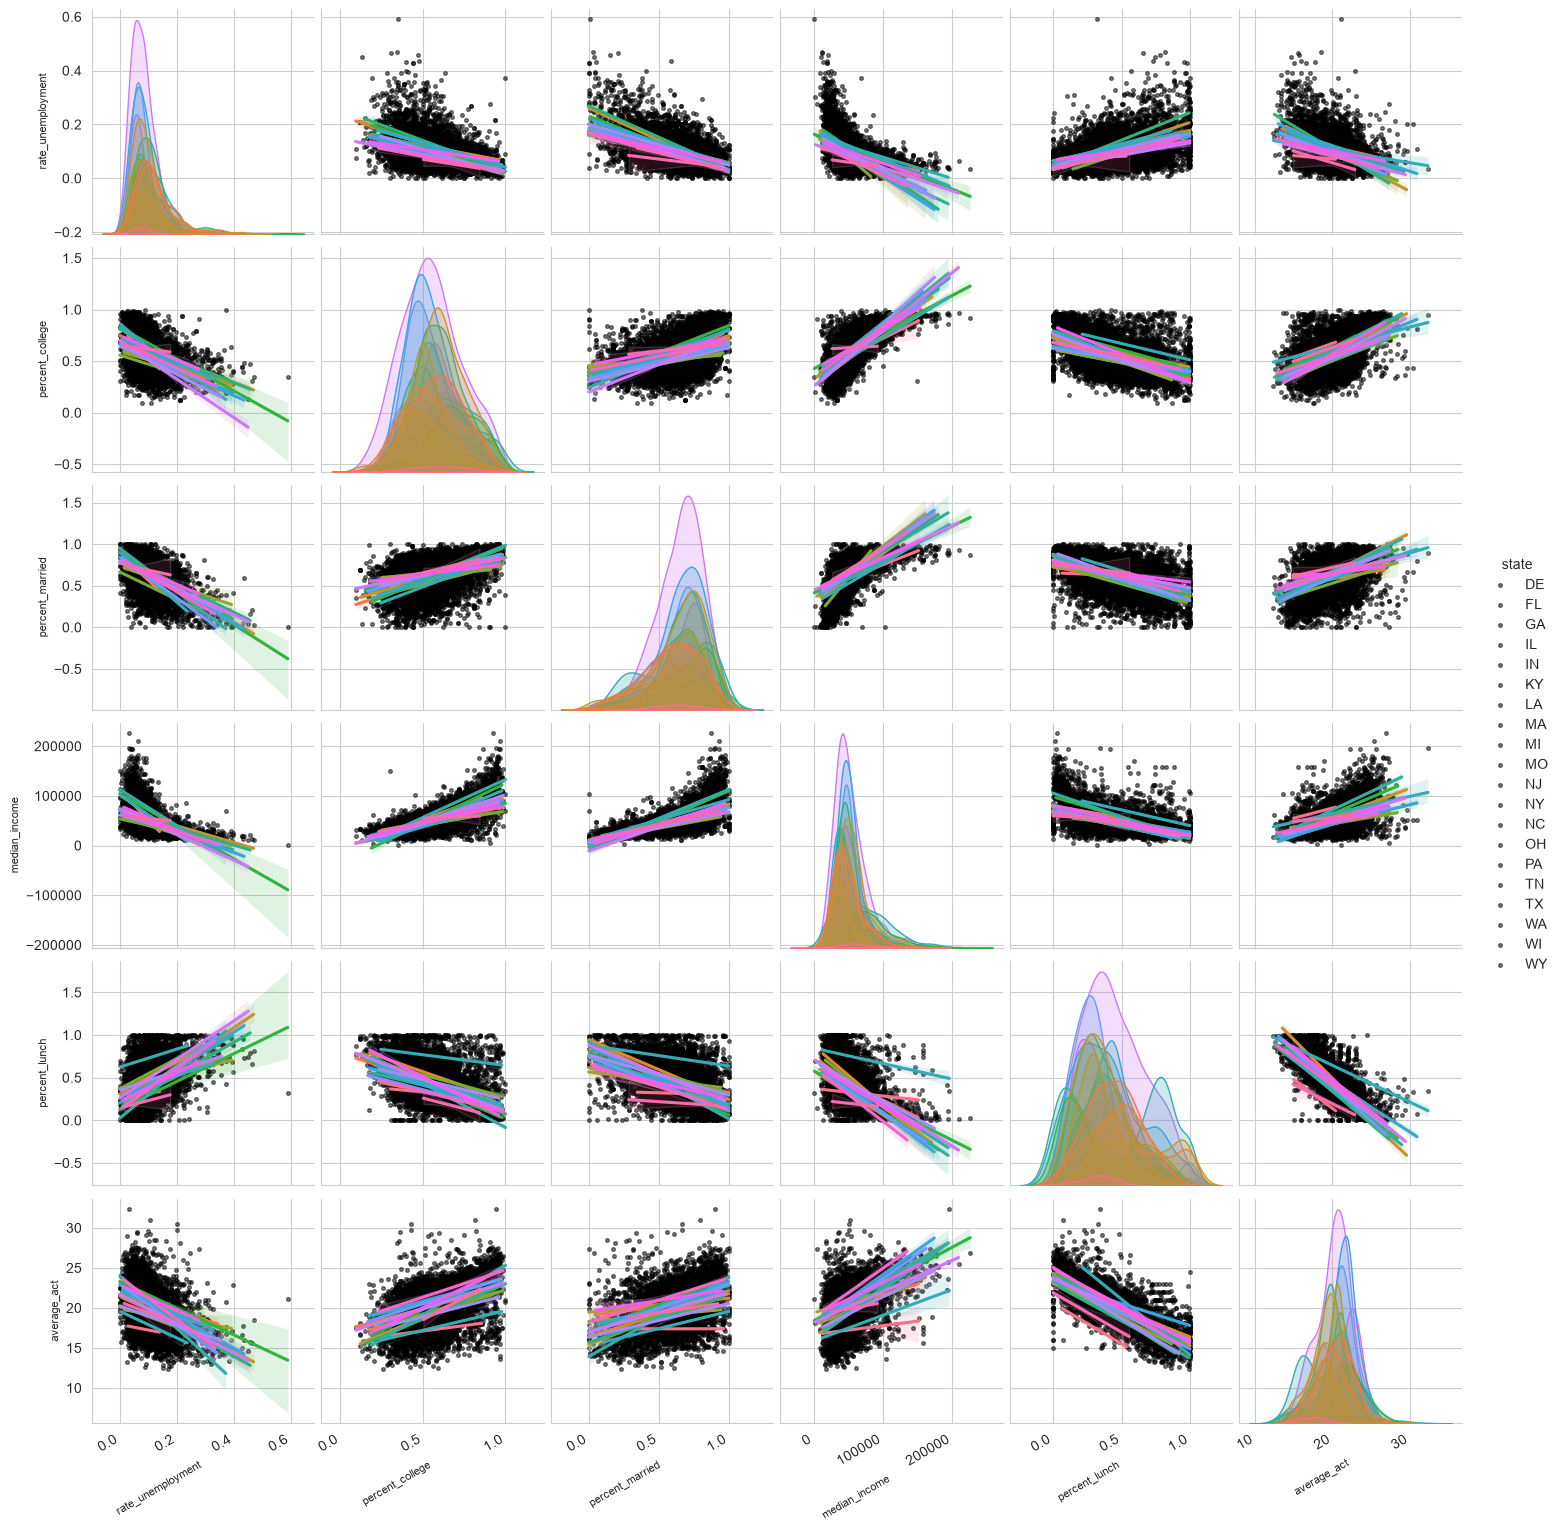

In [96]:
fig = sns.pairplot(
    data =df, 
    vars=numerical_predictors + ['average_act'],
    hue = 'state',
    kind = 'reg',
    plot_kws = {"scatter_kws":{'alpha':0.5, "color": 'k','s':7},
               },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis ='x', scilimits = (0,0))
    ax.set_xlabel(ax.get_xlabel(), fontsize =8, rotation = 30, ha = 'right')
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8)

    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')
plt.show()

seeing alot of variation in the predictors by state.

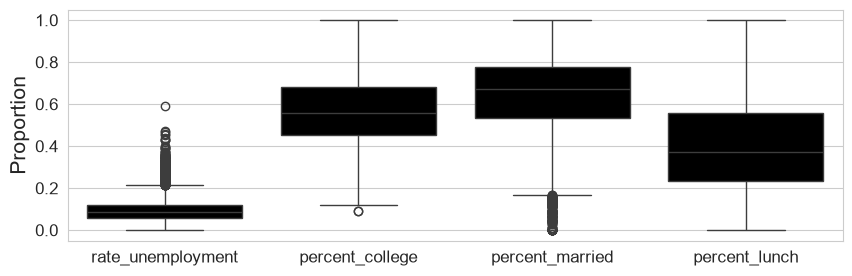

In [98]:
plt.figure(figsize =(10,3))
fractions = list (numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data= df[fractions], color = 'k')
plt.ylabel('Proportion', fontsize = 15)
plt.tick_params(labelsize =12)
plt.show()

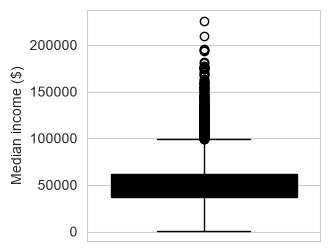

In [51]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df, y = 'median_income', color = 'k')
plt.ylabel('Median income ($)')

plt.show()

-numerical predictors appear to be related to the average ACT scores and their relationships look linear at first glance.
-there are a significant number of outliers in median income and unemployment rate.

## Regression Modeling 

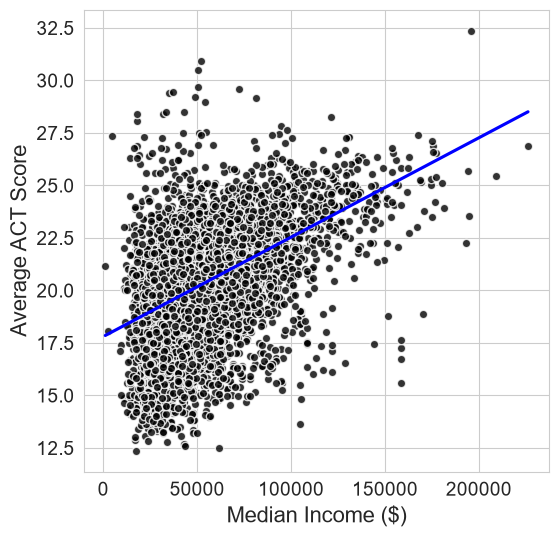

In [52]:
plt.figure(figsize=(6,6))

sns.regplot(data = df,
            x= 'median_income',
            y= 'average_act',
            color = 'blue',
            ci = False,
            scatter_kws= {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('Median Income ($)', fontsize = 16)
plt.ylabel('Average ACT Score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

In [53]:
import statsmodels.formula.api as smf
model_median_income = smf.ols(formula= 'average_act ~ median_income', data=df).fit()

In [54]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:22   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

In [55]:
#compute R-squared
model_median_income.rsquared

np.float64(0.21118648979300747)

In [56]:
#compute the Root Mean Square Error (RMSE)
y_hat = model_median_income.predict()

In [57]:
from sklearn.metrics import mean_squared_error
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(2.228)

In [58]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(df['average_act'], y_hat)

1.7129386980688577

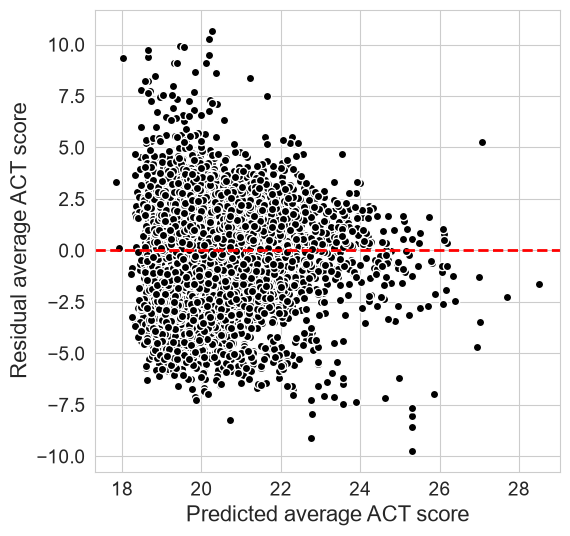

In [59]:
plt.figure(figsize = (6,6))

plt.plot(y_hat, model_median_income.resid, 'ko',mec = 'w')
plt.axhline(0,color ='r', linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

Potential quadratic has better line of fit for median income regression model 

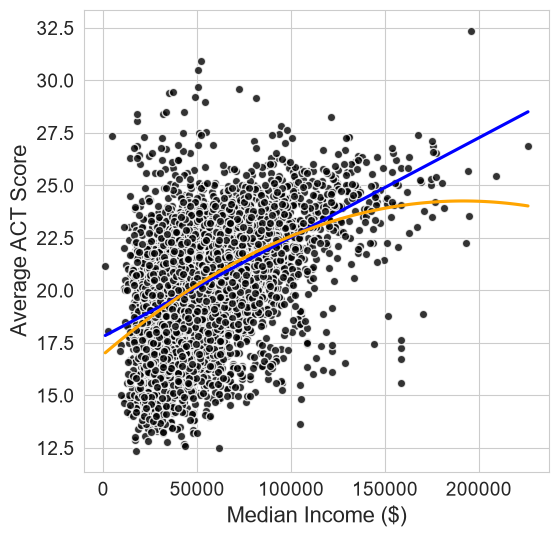

In [60]:
plt.figure(figsize=(6,6))

sns.regplot(data = df,
            x= 'median_income',
            y= 'average_act',
            color = 'blue',
            ci = False,
            scatter_kws= {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df, 
            x = "median_income",
            y= "average_act",
            order = 2, 
            color = 'orange', 
            ci = False, 
            scatter = False)

plt.xlabel('Median Income ($)', fontsize = 16)
plt.ylabel('Average ACT Score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

In [61]:
#fit quadratic linear regression model
model_median_income2 = smf.ols(
    formula ='average_act ~ median_income + I (median_income**2)',
    data = df).fit()

In [62]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:23   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

In [63]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

In [64]:
from statsmodels.stats.anova import anova_lm
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,35505.105960,1.0,359.906834,73.227974,1.395848e-17


In [65]:
#compute mean abs erro
mean_absolute_error(df['average_act'],model_median_income2.predict())

1.6972389257904357

The quadritic did not provide a better line of fit 

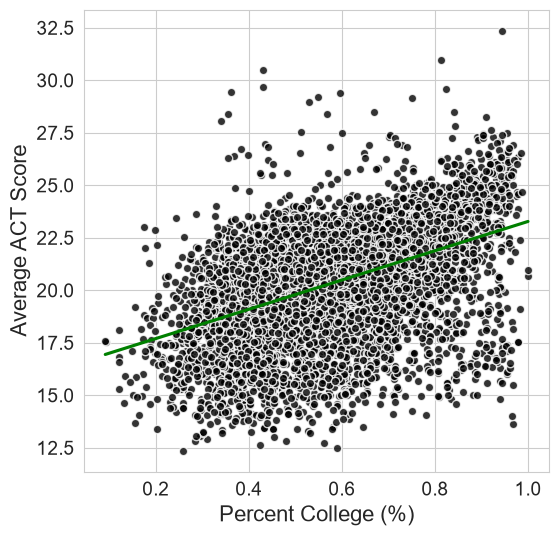

In [66]:
plt.figure(figsize=(6,6))

sns.regplot(data = df,
            x= 'percent_college',
            y= 'average_act',
            color = 'green',
            ci = False,
            scatter_kws= {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('Percent College (%)', fontsize = 16)
plt.ylabel('Average ACT Score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

In [67]:
model_percent_college = smf.ols(formula= 'average_act ~ percent_college', data=df).fit()

In [68]:
print(model_percent_college.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.210
Method:                 Least Squares   F-statistic:                     1922.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:24   Log-Likelihood:                -16048.
No. Observations:                7227   AIC:                         3.210e+04
Df Residuals:                    7225   BIC:                         3.211e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          16.3039      0.095    1

In [69]:
y_hat = model_percent_college.predict()

In [70]:
mean_absolute_error(df['average_act'], y_hat)

1.7169024235889787

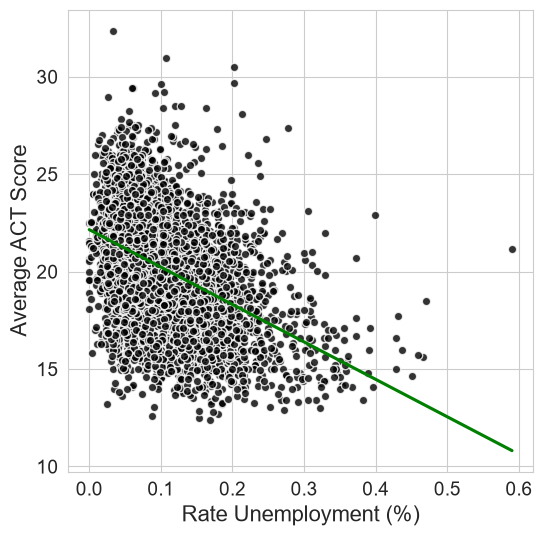

In [71]:
plt.figure(figsize=(6,6))

sns.regplot(data = df,
            x= 'rate_unemployment',
            y= 'average_act',
            color = 'green',
            ci = False,
            scatter_kws= {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('Rate Unemployment (%)', fontsize = 16)
plt.ylabel('Average ACT Score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

In [72]:
model_rate_unemployment = smf.ols(formula= 'average_act ~ rate_unemployment', data=df).fit()

In [73]:
print(model_rate_unemployment.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.188
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     1669.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:25   Log-Likelihood:                -16149.
No. Observations:                7227   AIC:                         3.230e+04
Df Residuals:                    7225   BIC:                         3.232e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.1512      0.05

In [74]:
y_hat = model_rate_unemployment.predict()

In [75]:
mean_absolute_error(df['average_act'], y_hat)

1.742189379673507

#Multiple Linear regression

In [99]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + state',
    data= df).fit()

In [100]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     635.2
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:25:24   Log-Likelihood:                -12793.
No. Observations:                7227   AIC:                         2.564e+04
Df Residuals:                    7202   BIC:                         2.581e+04
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            18.7258      0.31

In [101]:
y_hat = model.predict()

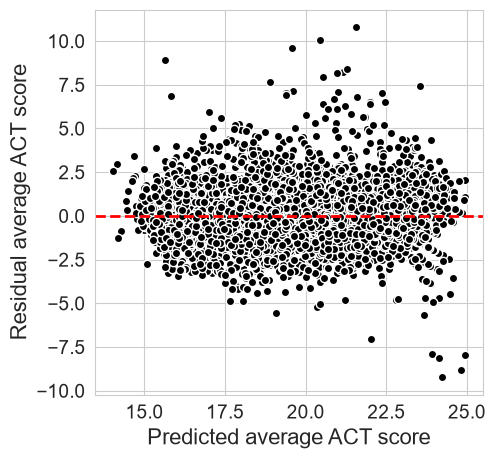

In [102]:
plt.figure(figsize = (5,5))

plt.plot(y_hat, model.resid, 'ko', mec= 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

In [103]:
mean_absolute_error(df['average_act'], model.predict())

1.0278330737213963

multiple linear regression model with ALL socioeconomic predictors CAN predict ACT scores with an average error of about 1 point using these predictors
residual plot suggests there will be limited improvement from adding transformations of these predictors
2x predictors did NOT have significant coefficients
adding predictors to model may improve performance

In [104]:
#reduced model with siginificant predictors
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch', 
    data = df).fit()

In [105]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:25:31   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

In [106]:
y_hat = model_reduced.predict()

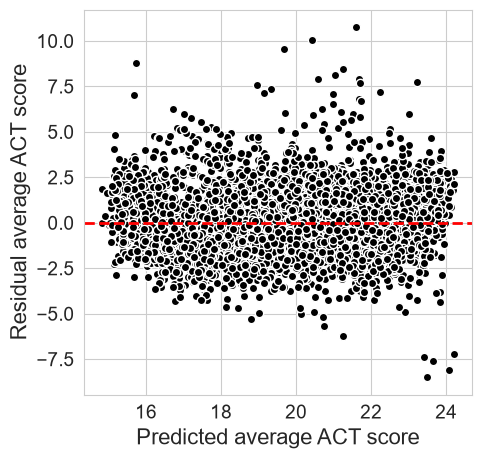

In [107]:
plt.figure(figsize = (5,5))

plt.plot(y_hat, model_reduced.resid, 'ko', mec='w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

In [108]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1454832950346348

In [109]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
              'R-squared':[r2_full, r2_reduced]},
             index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.0278,0.6792
reduced model,1.1455,0.6279


In [110]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7202.0,14587.606116,21.0,2329.013052,54.754739,8.191807e-213


#Scaling reduced model 
for mean =0  and st dev.= 1

In [111]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [89]:
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


In [90]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler().fit(df[predictor_variables])

In [91]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

In [92]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


In [93]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

In [94]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:13:26   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [95]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error':[mae_normalized, mae_reduced],
              'R-squared':[r2_normalized, r2_reduced]},
             index = ['noramlized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
noramlized model,1.1455,0.6279
reduced model,1.1455,0.6279


results
percent of students receiving reduced-price lunch at school is the strongest predictor for ACT score in this analysis
